# Stage 2 — AI-enhanced joint BiGRU (intent + slots), MASSIVE 1.0 en-US

This notebook trains and evaluates the **Stage-2** system. The model code is in
`joint_bigru_stage2.py`. It reuses the Stage-1 module (`joint_bigru_attention_crf.py`)
for dataset loading, BIO conversion and span decoding, so both stages are scored by the
same rules.

**Constraints followed:** official splits only (asserted below), the only model input is `utt`,
no pretrained model or pretrained word vectors (all weights start random), one joint model for both tasks,
total parameters ≤ 20M (asserted below).

### Weaknesses found in the Stage-1 baseline and what we changed
| # | Stage-1 weakness (diagnosis) | Stage-2 change |
|---|---|---|
| 1 | ~17% of dev/test utterances contain a word not in the training vocab, and every training word *is* in the vocab, so the `<unk>` embedding is never trained | **Frequency-based word dropout** (word → `<unk>` with p = 0.25/(0.25+count)) and a **character CNN** so unseen words still get a representation |
| 2 | The CRF can output invalid BIO sequences (e.g. `O → I-time`), which produce broken spans | **CRF with hard BIO constraints** on start and transition scores |
| 3 | Slot tagging can't see the predicted intent | **Intent-conditioned slot emissions** (the sentence vector is fed to every token's slot head) |
| 4 | Intent uses a single attention pooling; encoder is small (128/direction) | **Attention + max pooling**, BiGRU 256/direction |
| 5 | Fixed LR; still improving at epoch 30; 70 s/epoch on MPS | **AdamW + warm-up + cosine decay**, intent label smoothing 0.1. Runs on CPU: deterministic, and ~2x faster after replacing `nn.Conv1d` with an identical unfold+Linear |

### Tuning runs (selected on **validation** only; 40 epochs each, seed 42)
| Run | Change vs. previous | Val intent (%) | Val slot F1 (%) | Val combined |
|---|---|---|---|---|
| A | all changes above + residual 8-head self-attention, dropout 0.4 / emb 0.25 | 82.05 | 76.22 | 79.13 |
| B | A without self-attention | 85.83 | 79.45 | 82.64 |
| **C** | **B with dropout 0.3 / emb 0.15 (selected)** | **85.69** | **80.33** | **83.01** |
| D | B with dropout 0.5 / emb 0.3 | 83.92 | 78.65 | 81.29 |

Self-attention was rejected: with it the model learned much more slowly and ended about 3.5 points lower on combined validation score.
Config C is retrained from scratch below. Its numbers can differ slightly from the tuning run because this run uses 8 CPU threads instead of 4.

In [1]:
import json, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

import joint_bigru_attention_crf as stage1
import joint_bigru_stage2 as s2

DATA_PATH = Path("1.0/data/en-US.jsonl")
OUTPUT_DIR = Path("stage2_enhanced_outputs")
print("torch", torch.__version__)

torch 2.9.0


## 1. Load and verify the dataset (official partitions)

In [2]:
data = s2.prepare(DATA_PATH)          # calls stage1.read_data, which asserts the split sizes
splits = data["splits"]
print({k: len(v) for k, v in splits.items()})
assert len(splits["train"]) == 11514
assert len(splits["dev"]) == 2033
assert len(splits["test"]) == 2974

Dataset split sizes: {'train': 11514, 'dev': 2033, 'test': 2974}
Vocabulary size: 5146
Number of intents: 60
Number of BIO tags: 111


Character vocabulary size: 34
{'train': 11514, 'dev': 2033, 'test': 2974}


## 2. Preprocessing: tokens, characters, BIO tags (vocabularies from train only)

In [3]:
ex = data["datasets"]["train"][0]
record = splits["train"][0]
words, tags = stage1.record_to_tokens_tags(record)
print("utt      :", record["utt"])
print("annot_utt:", record["annot_utt"])
print("intent   :", record["intent"])
for w, t in zip(words, tags):
    print(f"  {w:10s} {t}")
print("gold slots:", ex["gold_slots"])
print("word vocab:", len(data["vocab"]), "| char vocab:", len(data["char_to_id"]),
      "| intents:", len(data["intent_to_id"]), "| BIO tags:", len(data["tag_to_id"]))

utt      : wake me up at nine am on friday
annot_utt: wake me up at [time : nine am] on [date : friday]
intent   : alarm_set
  wake       O
  me         O
  up         O
  at         O
  nine       B-time
  am         I-time
  on         O
  friday     B-date
gold slots: {('time', 'nine am'), ('date', 'friday')}
word vocab: 5146 | char vocab: 34 | intents: 60 | BIO tags: 111


### Diagnosis: out-of-vocabulary words (motivates word dropout + char-CNN)

In [4]:
train_counts = Counter(w.lower() for r in splits["train"] for w in stage1.record_to_tokens_tags(r)[0])
print("training word types:", len(train_counts), "| seen once:", sum(c == 1 for c in train_counts.values()))
for split in ["dev", "test"]:
    toks = [[w.lower() for w in stage1.record_to_tokens_tags(r)[0]] for r in splits[split]]
    n_tok = sum(map(len, toks)); n_oov = sum(w not in train_counts for t in toks for w in t)
    n_utt = sum(any(w not in train_counts for w in t) for t in toks)
    print(f"{split}: {100*n_oov/n_tok:.2f}% of tokens OOV, {100*n_utt/len(toks):.2f}% of utterances contain an OOV token")
print("Times <unk> appears in the Stage-1 training inputs:",
      sum(int((e['tokens'] == 1).sum()) for e in data['datasets']['train']))

training word types: 5144 | seen once: 2420
dev: 3.08% of tokens OOV, 17.27% of utterances contain an OOV token
test: 3.23% of tokens OOV, 18.19% of utterances contain an OOV token
Times <unk> appears in the Stage-1 training inputs: 0


## 3. Shared evaluation functions
`s2.compute_metrics` gives **intent accuracy** = 100 × correct / N and **slot micro-F1** =
100 × 2TP / (2TP + FP + FN) over exact `(slot type, span text)` pairs pooled across all utterances.
Spans are decoded with Stage-1's `decode_slots`. To check the scorer, we reload the
**Stage-1 checkpoint**, score it with this function, and compare against the Stage-1 module's own `evaluate`.

In [5]:
def evaluate_stage1_checkpoint(path, split):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = stage1.JointBiGRUAttentionCRF(len(ck["vocab"]), len(ck["intent_to_id"]), len(ck["tag_to_id"]))
    m.load_state_dict(ck["model"]); m.eval()
    id_to_tag = {i: t for t, i in ck["tag_to_id"].items()}
    loader = DataLoader(stage1.MassiveDataset(splits[split], ck["vocab"], ck["intent_to_id"], ck["tag_to_id"]),
                        batch_size=64, collate_fn=stage1.collate)
    pi, gi, ps, gs = [], [], [], []
    with torch.no_grad():
        for b in loader:
            out = m(b["tokens"], b["mask"])
            pi += out["intent_logits"].argmax(1).tolist(); gi += b["intents"].tolist()
            for utt, path_, gold in zip(b["utts"], m.crf.decode(out["emissions"], mask=b["mask"]), b["gold_slots"]):
                ps.append(stage1.decode_slots(utt, path_, id_to_tag)); gs.append(gold)
    shared = s2.compute_metrics(pi, gi, ps, gs)
    own = stage1.evaluate(m, loader, "cpu", id_to_tag)
    assert abs(shared["intent_accuracy"] - own["intent_accuracy"]) < 1e-9
    assert abs(shared["slot_micro_f1"] - own["slot_micro_f1"]) < 1e-9
    total = sum(p.numel() for p in m.parameters())
    return shared, total, ck["epoch"]

STAGE1_CKPT = "stage2_outputs/best_bigru_attention_crf.pt"
stage1_results = {}
for split in ["dev", "test"]:
    res, stage1_params, stage1_epoch = evaluate_stage1_checkpoint(STAGE1_CKPT, split)
    stage1_results[split] = res
    print(f"Stage-1 {split:4s}: intent {res['intent_accuracy']:.2f}% | slot micro-F1 {res['slot_micro_f1']:.2f}%")
print("Shared scorer matches the Stage-1 evaluate() exactly.")

Stage-1 dev : intent 84.01% | slot micro-F1 78.98%


Stage-1 test: intent 82.82% | slot micro-F1 75.63%
Shared scorer matches the Stage-1 evaluate() exactly.


## 4. Stage-2 model
**Inputs:** lower-cased word ids and per-word character ids (from `utt` only).
**Encoder:** [word embedding (300, random init) ‖ char-CNN (kernels 2/3/4 × 64 filters)] → 2-layer BiGRU (256/dir)
(dropout 0.3, embedding dropout 0.15).
**Intent head:** [attention pooling ‖ max pooling] → MLP → 60 intents.
**Slot head:** [token state ‖ tanh(W·sentence vector)] → MLP → BIO emissions → BIO-constrained CRF.
**Loss:** label-smoothed intent CE + CRF negative log-likelihood. **Optimizer:** AdamW, linear warm-up + cosine decay.
**Selection:** best validation combined score = (intent accuracy + slot micro-F1) / 2, the same criterion as Stage 1.

In [6]:
CONFIG = {**s2.DEFAULT_CONFIG, **{"threads": 8}}
print(json.dumps(CONFIG, indent=2))
model = s2.build_model(data, CONFIG)
print(model)
total_params, trainable_params = s2.count_parameters(model)
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
assert total_params <= 20_000_000
print("Within the 20M parameter budget.")
del model

{
  "seed": 42,
  "epochs": 40,
  "batch_size": 32,
  "lr": 0.002,
  "weight_decay": 0.01,
  "warmup_epochs": 1,
  "clip": 5.0,
  "unk_z": 0.25,
  "embed_dim": 300,
  "char_dim": 48,
  "char_filters": 64,
  "char_kernels": [
    2,
    3,
    4
  ],
  "hidden_size": 256,
  "layers": 2,
  "heads": 8,
  "use_self_attention": false,
  "intent_context_dim": 128,
  "dropout": 0.3,
  "emb_dropout": 0.15,
  "label_smoothing": 0.1,
  "threads": 8
}
JointBiGRUStage2(
  (embedding): Embedding(5146, 300, padding_idx=0)
  (char_cnn): CharCNN(
    (embedding): Embedding(34, 48, padding_idx=0)
    (convs): ModuleList(
      (0): Linear(in_features=96, out_features=64, bias=True)
      (1): Linear(in_features=144, out_features=64, bias=True)
      (2): Linear(in_features=192, out_features=64, bias=True)
    )
  )
  (emb_dropout): Dropout(p=0.15, inplace=False)
  (encoder): GRU(492, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (attn

## 5. Train and select the Stage-2 checkpoint (train split only; dev for selection)

In [7]:
run = s2.train_model(data, CONFIG, OUTPUT_DIR, checkpoint_name="best_bigru_stage2.pt")
history = run["history"]

Total parameters:     4,931,523
Trainable parameters: 4,931,523


Epoch  1/40 | train loss 9.9020 | val loss 4.3535 | val intent 64.49% | val slot F1 59.22% | combined 61.85 | 29.3s  <- best, saved


Epoch  2/40 | train loss 4.2431 | val loss 3.2722 | val intent 77.08% | val slot F1 71.42% | combined 74.25 | 37.2s  <- best, saved


Epoch  3/40 | train loss 3.3350 | val loss 3.0206 | val intent 79.39% | val slot F1 74.15% | combined 76.77 | 29.3s  <- best, saved


Epoch  4/40 | train loss 2.9151 | val loss 3.0396 | val intent 80.87% | val slot F1 76.76% | combined 78.81 | 28.9s  <- best, saved


Epoch  5/40 | train loss 2.6730 | val loss 2.9496 | val intent 82.88% | val slot F1 76.52% | combined 79.70 | 29.6s  <- best, saved


... (32 outputs left out)

Epoch 38/40 | train loss 1.0933 | val loss 3.5610 | val intent 85.15% | val slot F1 80.09% | combined 82.62 | 28.5s


Epoch 39/40 | train loss 1.0932 | val loss 3.5621 | val intent 85.15% | val slot F1 80.10% | combined 82.62 | 28.3s


Epoch 40/40 | train loss 1.0838 | val loss 3.5623 | val intent 85.19% | val slot F1 80.07% | combined 82.63 | 29.1s



Total training time: 19.4 min
Best epoch: 35
Best validation score (combined): 82.72 (intent 85.24%, slot F1 80.21%)
Checkpoint: stage2_enhanced_outputs/best_bigru_stage2.pt


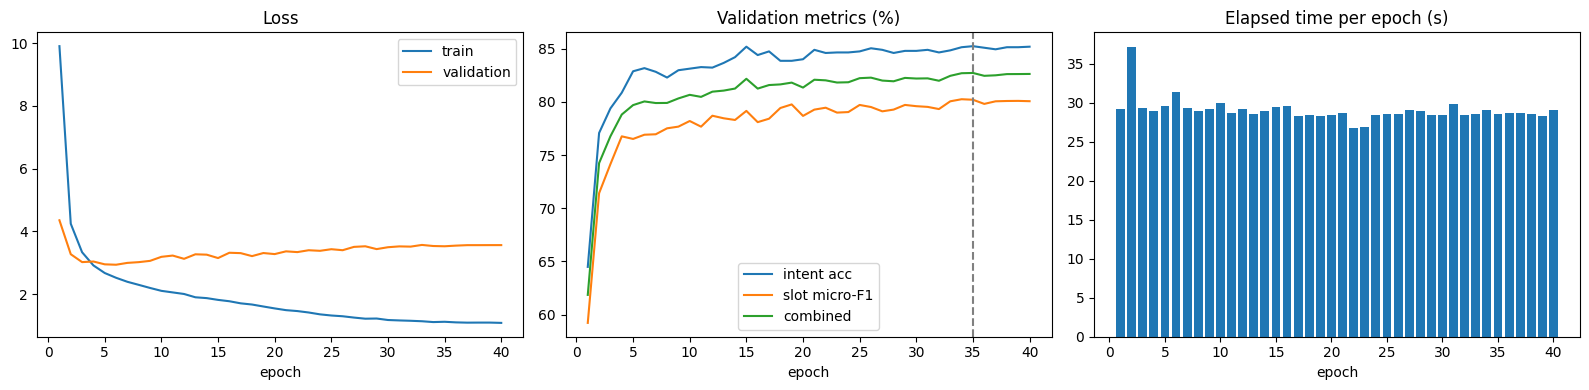

Best epoch: 35
Best validation score (combined): 82.72 (intent 85.24%, slot micro-F1 80.21%)
Checkpoint filename: stage2_enhanced_outputs/best_bigru_stage2.pt


In [8]:
ep = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ep, [h["train_loss"] for h in history], label="train")
axes[0].plot(ep, [h["validation_loss"] for h in history], label="validation")
axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
axes[1].plot(ep, [h["validation_intent_accuracy"] for h in history], label="intent acc")
axes[1].plot(ep, [h["validation_slot_micro_f1"] for h in history], label="slot micro-F1")
axes[1].plot(ep, [h["selection_score"] for h in history], label="combined")
axes[1].axvline(run["best"]["epoch"], ls="--", c="grey")
axes[1].set(title="Validation metrics (%)", xlabel="epoch"); axes[1].legend()
axes[2].bar(ep, [h["epoch_seconds"] for h in history])
axes[2].set(title="Elapsed time per epoch (s)", xlabel="epoch")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150); plt.show()

best = run["best"]
print(f"Best epoch: {best['epoch']}")
print(f"Best validation score (combined): {best['score']:.2f} "
      f"(intent {best['intent_accuracy']:.2f}%, slot micro-F1 {best['slot_micro_f1']:.2f}%)")
print(f"Checkpoint filename: {run['checkpoint']}")

## 6. Final evaluation of the Stage-2 checkpoint (reloaded, no further training)

In [9]:
model, saved = s2.load_checkpoint(run["checkpoint"], data)
print("Loaded", run["checkpoint"], "from epoch", saved["epoch"])
loaders = s2.make_loaders(data, 32, 0)
preds, stage2_results = {}, {}
for split in ["dev", "test"]:
    preds[split] = s2.predict(model, loaders[split], "cpu", data["id_to_tag"])
    stage2_results[split] = s2.compute_metrics(preds[split]["pred_intents"], preds[split]["gold_intents"],
                                               preds[split]["pred_slots"], preds[split]["gold_slots"])
    r = stage2_results[split]
    print(f"Stage-2 {split:4s}: intent {r['intent_accuracy']:.2f}% | slot micro-F1 {r['slot_micro_f1']:.2f}%")
assert abs(stage2_results["dev"]["combined"] - saved["validation_score"]) < 1e-9, "dev score differs from saved best"
print("Reloaded validation score equals the best validation score saved during training.")

Loaded stage2_enhanced_outputs/best_bigru_stage2.pt from epoch 35


Stage-2 dev : intent 85.24% | slot micro-F1 80.21%


Stage-2 test: intent 84.63% | slot micro-F1 78.37%
Reloaded validation score equals the best validation score saved during training.


## 7. Stage-1 vs Stage-2 comparison (all numbers computed above)

In [10]:
import pandas as pd
rows = []
for name, res, tot, trn, n_ep in [
    ("Stage-1 system", stage1_results, stage1_params, stage1_params, stage1_epoch),
    ("Stage-2 system", stage2_results, total_params, trainable_params, best["epoch"]),
]:
    for split, label in [("dev", "Validation"), ("test", "Test")]:
        rows.append({"Model version": name, "Split": label, "Total # parameters": f"{tot:,}",
                     "Total # trainable parameters": f"{trn:,}",
                     "Intent accuracy (%)": f"{res[split]['intent_accuracy']:.2f}",
                     "Slot micro-F1 (%)": f"{res[split]['slot_micro_f1']:.2f}",
                     "Number of epochs (best ckpt)": n_ep})
table = pd.DataFrame(rows)
table.to_csv(OUTPUT_DIR / "comparison_table.csv", index=False)
table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs (best ckpt)
0,Stage-1 system,Validation,"1,044,435","1,044,435",84.01,78.98,30
1,Stage-1 system,Test,"1,044,435","1,044,435",82.82,75.63,30
2,Stage-2 system,Validation,"4,931,523","4,931,523",85.24,80.21,35
3,Stage-2 system,Test,"4,931,523","4,931,523",84.63,78.37,35


## 8. Error analysis on the test set (Stage-2)

In [11]:
id_to_intent = {i: n for n, i in data["intent_to_id"].items()}
p = preds["test"]
intent_errors = Counter((id_to_intent[g], id_to_intent[q]) for g, q in zip(p["gold_intents"], p["pred_intents"]) if g != q)
print("Most frequent intent confusions (gold -> predicted):")
for (g, q), c in intent_errors.most_common(10):
    print(f"  {c:3d}  {g} -> {q}")

per_type = Counter(); fn_type = Counter(); fp_type = Counter()
for ps, gs in zip(p["pred_slots"], p["gold_slots"]):
    for t, _ in gs: per_type[t] += 1
    for t, _ in gs - ps: fn_type[t] += 1
    for t, _ in ps - gs: fp_type[t] += 1
print("\nSlot types with the most errors (gold count, missed, spurious):")
for t, _ in (fn_type + fp_type).most_common(10):
    print(f"  {t:20s} gold={per_type[t]:4d}  FN={fn_type[t]:3d}  FP={fp_type[t]:3d}")

Most frequent intent confusions (gold -> predicted):
   23  general_quirky -> qa_factoid
   10  qa_factoid -> general_quirky
    9  general_quirky -> news_query
    9  general_quirky -> calendar_query
    8  play_game -> play_music
    7  calendar_query -> calendar_set
    7  calendar_set -> calendar_query
    7  cooking_recipe -> general_quirky
    6  news_query -> general_quirky
    6  social_post -> general_quirky

Slot types with the most errors (gold count, missed, spurious):
  event_name           gold= 260  FN= 68  FP= 60
  place_name           gold= 281  FN= 60  FP= 55
  person               gold= 219  FN= 30  FP= 50
  time                 gold= 193  FN= 42  FP= 37
  date                 gold= 416  FN= 32  FP= 45
  food_type            gold=  72  FN= 24  FP= 33
  business_name        gold=  92  FN= 27  FP= 23
  weather_descriptor   gold=  82  FN= 18  FP= 24
  news_topic           gold=  49  FN= 20  FP= 20
  media_type           gold= 128  FN= 23  FP= 16


In [12]:
oov_flags = [any(w.lower() not in train_counts for w in stage1.record_to_tokens_tags(r)[0]) for r in splits["test"]]
for flag, name in [(True, "with OOV word"), (False, "no OOV word")]:
    idx = [i for i, f in enumerate(oov_flags) if f == flag]
    m = s2.compute_metrics([p["pred_intents"][i] for i in idx], [p["gold_intents"][i] for i in idx],
                           [p["pred_slots"][i] for i in idx], [p["gold_slots"][i] for i in idx])
    print(f"test utterances {name:14s} (n={len(idx):4d}): intent {m['intent_accuracy']:.2f}% | slot F1 {m['slot_micro_f1']:.2f}%")

print("\nExample errors:")
shown = 0
for i, (utt, gi, pi, gs, ps) in enumerate(zip(p["utts"], p["gold_intents"], p["pred_intents"], p["gold_slots"], p["pred_slots"])):
    if (gi != pi or gs != ps) and i % 7 == 0:
        print(f"- utt: {utt}")
        print(f"  intent gold={id_to_intent[gi]}  pred={id_to_intent[pi]}")
        print(f"  slots  gold={sorted(gs)}")
        print(f"         pred={sorted(ps)}")
        shown += 1
    if shown == 8:
        break

test utterances with OOV word  (n= 541): intent 72.27% | slot F1 61.58%
test utterances no OOV word    (n=2433): intent 87.38% | slot F1 82.78%

Example errors:
- utt: i want the status on my screen brightness
  intent gold=general_quirky  pred=general_quirky
  slots  gold=[]
         pred=[('device_type', 'screen')]
- utt: i like senatra songs
  intent gold=music_likeness  pred=music_likeness
  slots  gold=[('artist_name', 'senatra')]
         pred=[('music_genre', 'senatra')]
- utt: seven years
  intent gold=play_music  pred=general_quirky
  slots  gold=[('song_name', 'seven years')]
         pred=[]
- utt: play the second song from anirudh's song
  intent gold=play_music  pred=play_music
  slots  gold=[('artist_name', "anirudh's")]
         pred=[('artist_name', "anirudh's"), ('audiobook_name', 'the second')]
- utt: play a retro song in my playlist
  intent gold=play_music  pred=play_music
  slots  gold=[('music_genre', 'retro')]
         pred=[('song_name', 'retro')]
- utt: by get 